# Notebook 04: Explainable AI (XAI) Suite on Clean Hourly Data
## 1. Load Clean Hourly Dataset

In [1]:
import numpy as np, pandas as pd, shap, torch, torch.nn as nn, matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PowerTransformer
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import ExtraTreesClassifier
from xgboost import XGBClassifier
df = pd.read_csv(PROJECT_ROOT / '06_Data' / 'riyadh_hourly_clean_tvt.csv')
df['ts'] = pd.to_datetime(df['ts'])
target_cols = [c for c in df.columns if c.startswith('target_')]
feature_cols = [c for c in df.columns if c not in ['ts'] + target_cols]
print(f'Clean hourly rows: {len(df):,} | Features: {len(feature_cols)}')

Clean hourly rows: 86,928 | Features: 115


## 2. Reconstruct Exact Hourly Train (70%) / Val (15%) / Test (15%) Split

In [2]:
N = len(df); GAP_H = 360; STRIDE = 6
tr_end = int(N * 0.70); val_start = tr_end + GAP_H; val_end = int(N * 0.85); te_start = val_end + GAP_H
train_df = df.iloc[:tr_end:STRIDE].reset_index(drop=True)
test_df = df.iloc[te_start::STRIDE].reset_index(drop=True)
imp = SimpleImputer(strategy='median'); pt = PowerTransformer(method='yeo-johnson')
X_tr = pt.fit_transform(imp.fit_transform(train_df[feature_cols].values))
X_te = pt.transform(imp.transform(test_df[feature_cols].values))
y_tr = train_df['target_evt_any_168h'].values.astype(int)
y_te = test_df['target_evt_any_168h'].values.astype(int)
print(f'168h (7d) Test Positives: {y_te.sum()}/{len(y_te)} ({y_te.mean()*100:.1f}%)')

168h (7d) Test Positives: 739/2114 (35.0%)


## 3. Fit Reference XGBoost & ExtraTrees Models (168h Clean Forecast)

In [3]:
pw = float(np.sum(y_tr==0)/max(1,np.sum(y_tr==1)))
xgb = XGBClassifier(n_estimators=120, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, scale_pos_weight=pw, reg_lambda=2.0, random_state=42, n_jobs=-1, eval_metric='logloss').fit(X_tr, y_tr)
et = ExtraTreesClassifier(n_estimators=100, max_depth=8, min_samples_leaf=8, class_weight='balanced', random_state=42, n_jobs=-1).fit(X_tr, y_tr)
print(f'Test ROC-AUC -> XGBoost: {roc_auc_score(y_te, xgb.predict_proba(X_te)[:,1]):.4f} | ExtraTrees: {roc_auc_score(y_te, et.predict_proba(X_te)[:,1]):.4f}')

Test ROC-AUC -> XGBoost: 0.6987 | ExtraTrees: 0.6948


## 4. XAI-1: Global Gain & Test Permutation Importance (`n_jobs=1`)

In [4]:
perm_xgb = permutation_importance(xgb, X_te, y_te, n_repeats=8, random_state=42, scoring='roc_auc', n_jobs=1)
perm_et = permutation_importance(et, X_te, y_te, n_repeats=8, random_state=42, scoring='roc_auc', n_jobs=1)
print('Permutation importance computed on held-out Test.')

Permutation importance computed on held-out Test.


## 5. XAI-2: Exact Game-Theoretic SHAP (`shap.TreeExplainer`)

In [5]:
explainer = shap.TreeExplainer(xgb); shap_vals = explainer.shap_values(X_te)
xai_df = pd.DataFrame({'Feature': feature_cols, 'XGB_Gain': np.round(xgb.feature_importances_,5), 'ET_Gini': np.round(et.feature_importances_,5), 'XGB_Perm_ROC': np.round(perm_xgb.importances_mean,5), 'ET_Perm_ROC': np.round(perm_et.importances_mean,5), 'Mean_Abs_SHAP': np.round(np.mean(np.abs(shap_vals), axis=0),5)}).sort_values('Mean_Abs_SHAP', ascending=False)
xai_df.to_csv(XAI_DIR / 'nb04_xai_clean_hourly_importance.csv', index=False)
print(xai_df.head(15).to_string(index=False))

                       Feature  XGB_Gain  ET_Gini  XGB_Perm_ROC  ET_Perm_ROC  Mean_Abs_SHAP
                       sin_doy   0.06113  0.13477       0.16749      0.03060        0.71245
               dust_rate_4320h   0.01446  0.00715       0.00563      0.00049        0.52050
              hours_since_dust   0.01461  0.01838       0.01524     -0.00085        0.24132
                dust_rate_720h   0.01538  0.02220      -0.00183     -0.00126        0.17698
  era5_soil_moisture_7_to_28cm   0.01607  0.02349      -0.01419     -0.00803        0.12351
   era5_soil_moisture_0_to_7cm   0.03189  0.03212       0.00299     -0.00322        0.10673
                       cos_doy   0.01515  0.01505      -0.00612      0.00050        0.09449
sat_retrieved_pm10_detrended_z   0.03097  0.03091       0.00133      0.00031        0.08923
         phys_vpd_kpa_roll168h   0.01596  0.02346       0.00474      0.00540        0.08831
                          gust   0.01465  0.00455      -0.00796     -0.00035    

## 6. Plot: SHAP Mean |Impact| vs Test Permutation Importance

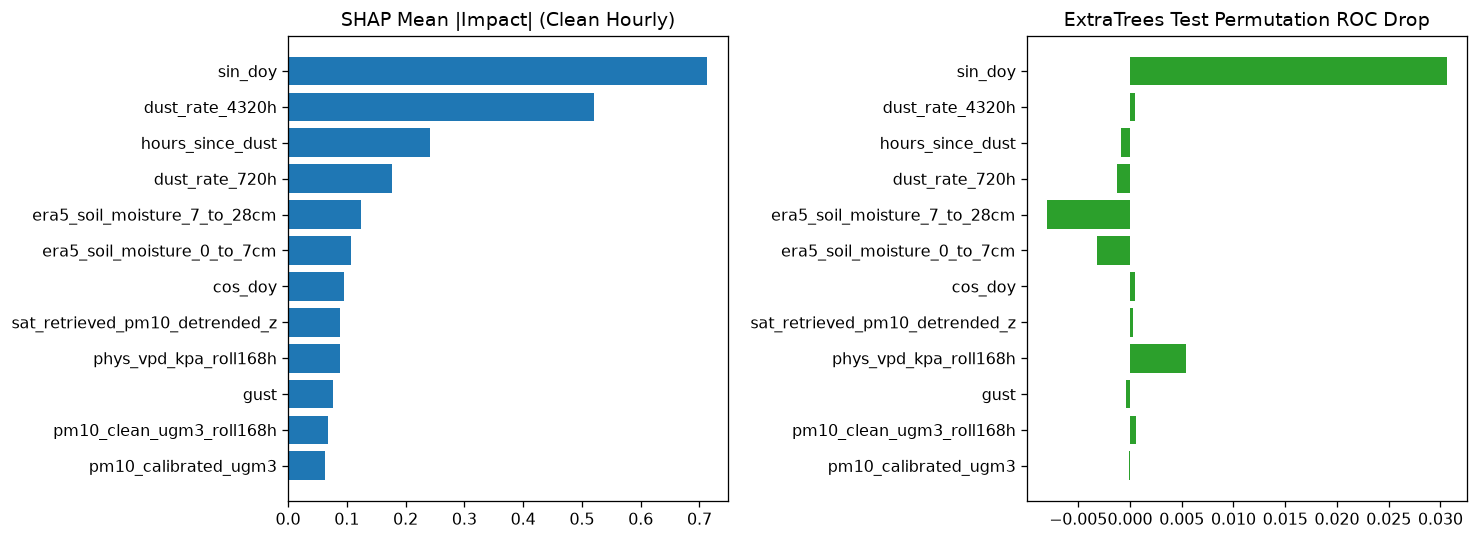

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
t12 = xai_df.head(12).iloc[::-1]
axes[0].barh(t12['Feature'], t12['Mean_Abs_SHAP'], color='#1f77b4'); axes[0].set_title('SHAP Mean |Impact| (Clean Hourly)')
axes[1].barh(t12['Feature'], t12['ET_Perm_ROC'], color='#2ca02c'); axes[1].set_title('ExtraTrees Test Permutation ROC Drop')
plt.tight_layout()

## 7. Plot: SHAP Directional Beeswarm Scatter (Top 10 Features)

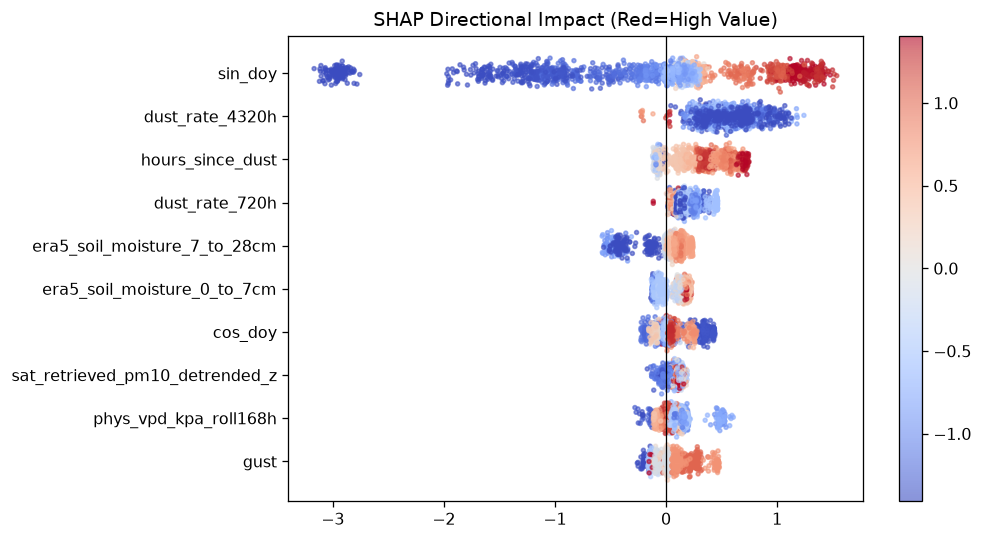

In [7]:
top10 = xai_df.head(10)['Feature'].tolist()
fig, ax = plt.subplots(figsize=(9, 4.8))
for ri, fn in enumerate(reversed(top10)):
    j = feature_cols.index(fn); sv = shap_vals[:, j]; fv = X_te[:, j]
    sc = ax.scatter(sv, ri + np.random.default_rng(42).normal(0,0.12,len(sv)), c=np.clip(fv,-2.5,2.5), cmap='coolwarm', s=6, alpha=0.6)
ax.set_yticks(range(10)); ax.set_yticklabels(list(reversed(top10))); ax.axvline(0, color='black', lw=0.8)
ax.set_title('SHAP Directional Impact (Red=High Value)'); plt.colorbar(sc, ax=ax); plt.tight_layout()

## 8. Modality-Level Attribution Balance Audit

In [8]:
def grp(f):
    if 'era5' in f or 'phys' in f or 'sp_' in f or 't2m_' in f or 'ws_' in f or 'dryness' in f: return 'ERA5_Physics'
    if 'sat_' in f or 'aod' in f: return 'Satellite_Detrended'
    if 'cams' in f or 'nwp' in f: return 'CAMS_NWP_Detrended'
    if 'doy' in f or 'hour' in f: return 'Calendar_Diurnal'
    return 'Ground_METAR'
xai_df['Modality'] = [grp(f) for f in xai_df['Feature']]
mod_sum = xai_df.groupby('Modality')[['Mean_Abs_SHAP','XGB_Gain','ET_Gini']].sum()
print(mod_sum.round(4).to_string())

                     Mean_Abs_SHAP  XGB_Gain  ET_Gini
Modality                                             
CAMS_NWP_Detrended          0.0591    0.0331   0.0354
Calendar_Diurnal            1.0483    0.0909   0.1690
ERA5_Physics                0.7651    0.3434   0.2887
Ground_METAR                1.2222    0.4571   0.4384
Satellite_Detrended         0.1536    0.0755   0.0685


## 9. Modality Share Chart

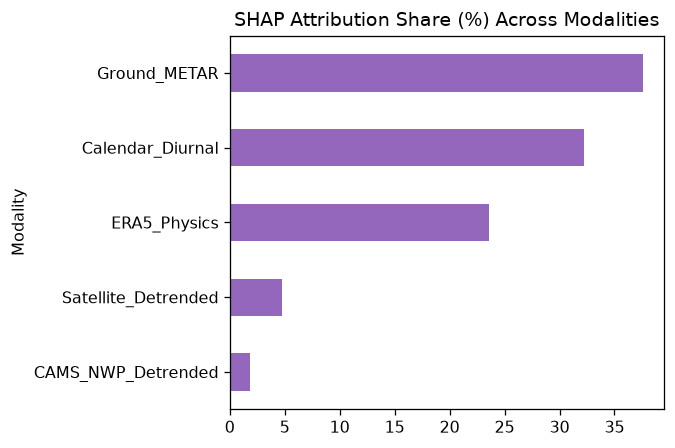

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
(mod_sum['Mean_Abs_SHAP']/mod_sum['Mean_Abs_SHAP'].sum()*100).sort_values().plot(kind='barh', ax=ax, color='#9467bd')
ax.set_title('SHAP Attribution Share (%) Across Modalities'); plt.tight_layout()

## 10. Local SHAP Explanation: Highest-Risk Test Timestamp

In [10]:
p_te = xgb.predict_proba(X_te)[:, 1]; i_hi = int(np.argmax(p_te))
s_hi = pd.Series(shap_vals[i_hi], index=feature_cols).sort_values(key=np.abs, ascending=False)
print(f'Highest Risk Test Hour: {test_df.iloc[i_hi]["ts"]} | P={p_te[i_hi]:.3f} | Obs={y_te[i_hi]}')
print(s_hi.head(8).round(4).to_string())

Highest Risk Test Hour: 2024-06-20 04:00:00 | P=0.983 | Obs=1
pm10_calibrated_ugm3    1.1002
dust_rate_4320h         0.5380
sin_doy                 0.3764
cos_doy                 0.3106
has_wxcode              0.2688
pm10_clean_ugm3         0.2616
dust_rate_720h          0.2503
vsby                    0.2028


## 11. Local SHAP Waterfall Plot (Highest-Risk Test Hour)

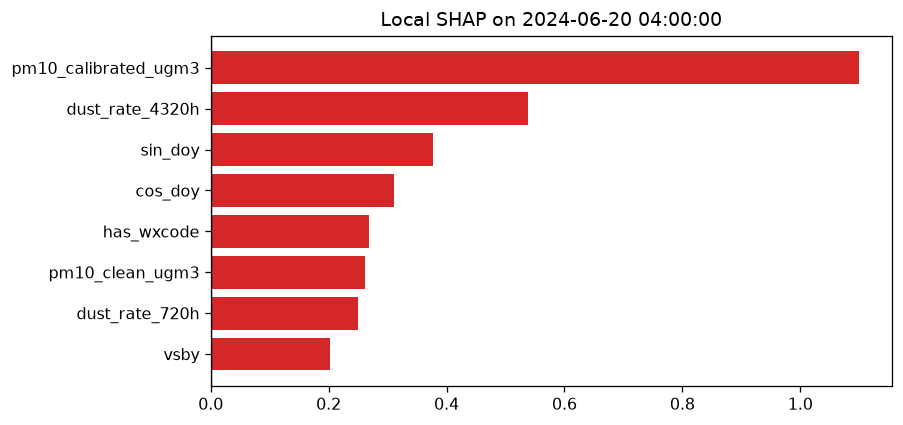

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.8)); t8 = s_hi.head(8).iloc[::-1]
ax.barh(t8.index, t8.values, color=['#d62728' if v>0 else '#1f77b4' for v in t8.values])
ax.axvline(0, color='black', lw=0.8); ax.set_title(f'Local SHAP on {test_df.iloc[i_hi]["ts"]}'); plt.tight_layout()

## 12. Local SHAP Explanation: Lowest-Risk Clear Timestamp

In [12]:
i_lo = int(np.argmin(p_te)); s_lo = pd.Series(shap_vals[i_lo], index=feature_cols).sort_values(key=np.abs, ascending=False)
print(f'Lowest Risk Test Hour: {test_df.iloc[i_lo]["ts"]} | P={p_te[i_lo]:.3f} | Obs={y_te[i_lo]}')
print(s_lo.head(8).round(4).to_string())

Lowest Risk Test Hour: 2023-09-24 10:00:00 | P=0.051 | Obs=0
sin_doy                       -3.0637
hours_since_dust               0.3122
dust_rate_4320h                0.2739
era5_soil_moisture_0_to_7cm   -0.1160
cos_doy                       -0.0796
phys_vpd_kpa_roll168h          0.0750
nwp_bias_proxy                 0.0699
gust                          -0.0692


## 13. XAI-3: 1D Partial Dependence & ICE Curves (Top 4 Drivers)

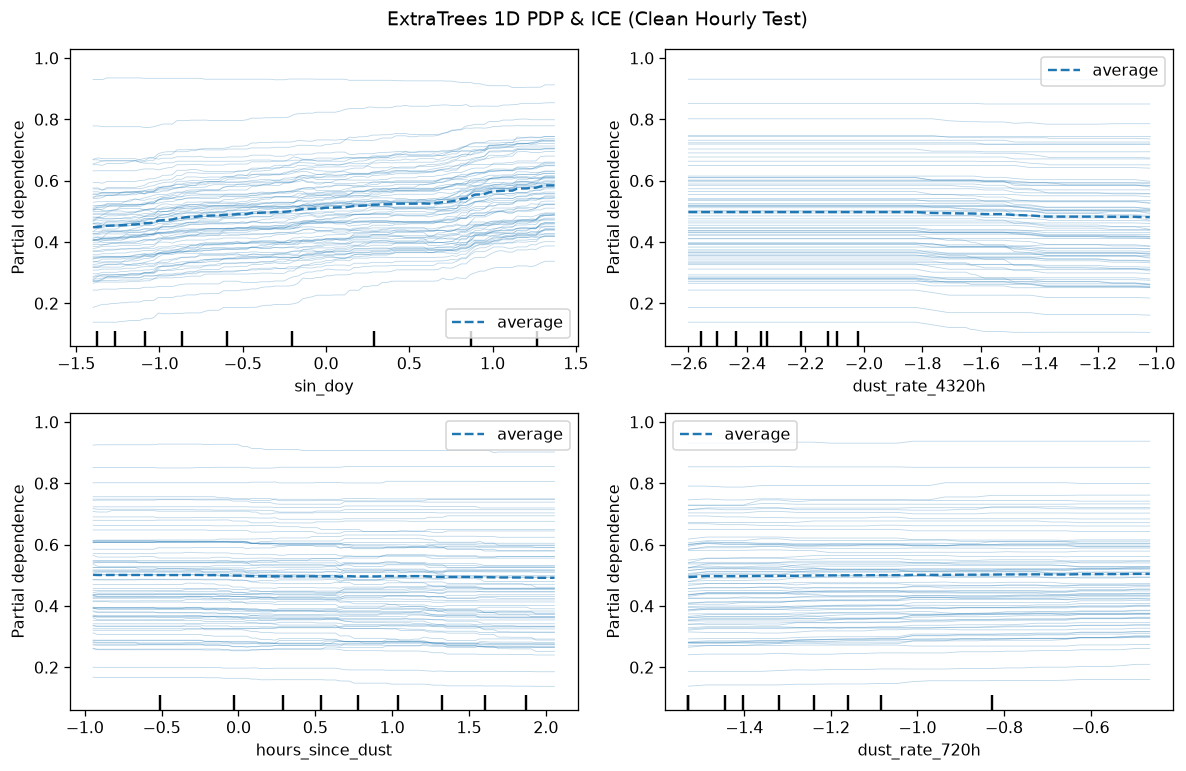

In [13]:
top4_i = [feature_cols.index(f) for f in xai_df.head(4)['Feature'].tolist()]
fig, axes = plt.subplots(2, 2, figsize=(10.5, 6.8))
PartialDependenceDisplay.from_estimator(et, X_te, top4_i, feature_names=feature_cols, kind='both', subsample=80, random_state=42, ax=axes.ravel())
plt.suptitle('ExtraTrees 1D PDP & ICE (Clean Hourly Test)'); plt.tight_layout()

## 14. 2D Partial Dependence Interaction (Top 2 Drivers)

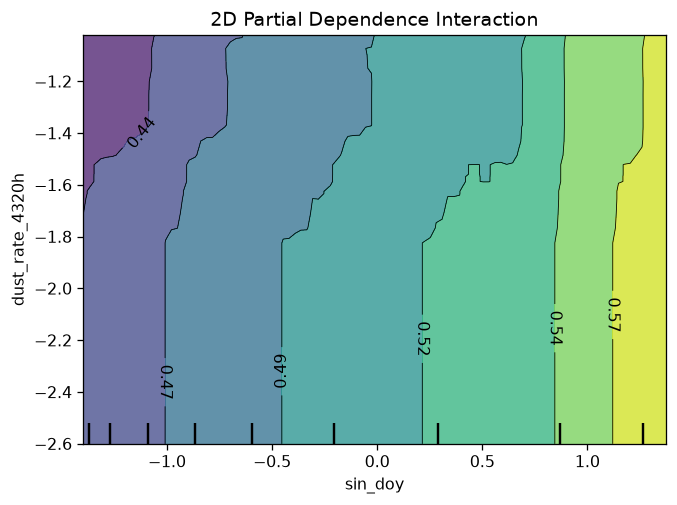

In [14]:
fig, ax = plt.subplots(figsize=(6, 4.5))
PartialDependenceDisplay.from_estimator(et, X_te, [(top4_i[0], top4_i[1])], feature_names=feature_cols, ax=ax)
ax.set_title('2D Partial Dependence Interaction'); plt.tight_layout()

## 15. XAI-4: Surrogate Decision Tree Rules (`max_depth=3`)

In [15]:
surr = DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=42).fit(test_df[feature_cols].fillna(0), (p_te>=0.5).astype(int))
print(f'Surrogate fidelity: {(surr.predict(test_df[feature_cols].fillna(0))==(p_te>=0.5)).mean()*100:.1f}%')
print(export_text(surr, feature_names=feature_cols))

Surrogate fidelity: 96.6%
|--- sin_doy <= -0.79
|   |--- era5_soil_moisture_7_to_28cm <= 0.07
|   |   |--- era5_surface_pressure <= 947.05
|   |   |   |--- class: 0
|   |   |--- era5_surface_pressure >  947.05
|   |   |   |--- class: 0
|   |--- era5_soil_moisture_7_to_28cm >  0.07
|   |   |--- sin_doy <= -0.98
|   |   |   |--- class: 0
|   |   |--- sin_doy >  -0.98
|   |   |   |--- class: 1
|--- sin_doy >  -0.79
|   |--- sin_doy <= -0.75
|   |   |--- class: 1
|   |--- sin_doy >  -0.75
|   |   |--- sin_doy <= -0.67
|   |   |   |--- class: 1
|   |   |--- sin_doy >  -0.67
|   |   |   |--- class: 1



## 16. Local Counterfactual Sensitivity (+1 SD Perturbation)

In [16]:
bp = p_te.mean(); cf = []
for f in xai_df.head(8)['Feature']:
    j = feature_cols.index(f); Xp = X_te.copy(); Xp[:,j] += 1.0
    cf.append({'Feature': f, 'Delta_P(+1SD)': round(xgb.predict_proba(Xp)[:,1].mean()-bp, 4)})
print(pd.DataFrame(cf).to_string(index=False))

                       Feature  Delta_P(+1SD)
                       sin_doy         0.1195
               dust_rate_4320h        -0.0906
              hours_since_dust         0.0442
                dust_rate_720h        -0.0256
  era5_soil_moisture_7_to_28cm         0.0070
   era5_soil_moisture_0_to_7cm         0.0102
                       cos_doy        -0.0065
sat_retrieved_pm10_detrended_z        -0.0082


## 17. XAI-5: Real PyTorch LSTM 24-Hour Lookback Temporal Saliency

In [17]:
torch.manual_seed(42); SEQ_LEN = 24
X_all_s = pt.transform(imp.transform(df[feature_cols].values))
tr_i = np.arange(SEQ_LEN, tr_end, STRIDE); te_i = np.arange(te_start, N, STRIDE)
X_tr_q = torch.tensor(np.array([X_all_s[i-SEQ_LEN+1:i+1] for i in tr_i], dtype=np.float32))
y_tr_q = torch.tensor(df.iloc[tr_i]['target_evt_any_168h'].values, dtype=torch.float32)
X_te_q = torch.tensor(np.array([X_all_s[i-SEQ_LEN+1:i+1] for i in te_i], dtype=np.float32), requires_grad=True)
class MiniLSTM(nn.Module):
    def __init__(self, d): super().__init__(); self.lstm = nn.LSTM(d, 32, batch_first=True); self.fc = nn.Linear(32, 1)
    def forward(self, x): o, _ = self.lstm(x); return self.fc(o[:,-1,:]).squeeze(-1)
ml = MiniLSTM(len(feature_cols)); opt = torch.optim.Adam(ml.parameters(), lr=2e-3); lf = nn.BCEWithLogitsLoss()
for _ in range(12): opt.zero_grad(); lf(ml(X_tr_q), y_tr_q).backward(); opt.step()
ml.eval(); ml(X_te_q).sum().backward()
temp_sal = X_te_q.grad.abs().mean(dim=(0,2)).detach().numpy(); feat_sal = X_te_q.grad.abs().mean(dim=(0,1)).detach().numpy()
print('24h Temporal Saliency mean:', round(float(temp_sal.mean()), 5))

24h Temporal Saliency mean: 0.00093


## 18. Plot: 24-Hour Lookback Saliency (Lag -23h to 0h)

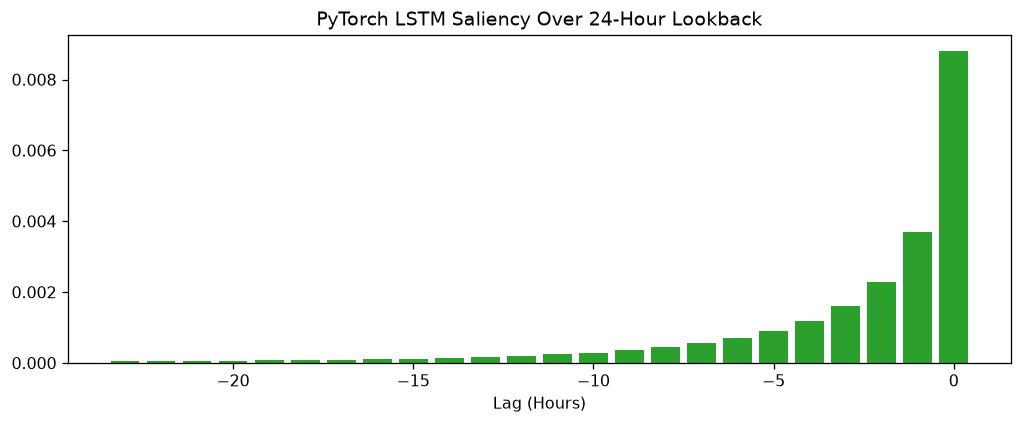

In [18]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(np.arange(-SEQ_LEN+1, 1), temp_sal, color='#2ca02c')
ax.set_title('PyTorch LSTM Saliency Over 24-Hour Lookback'); ax.set_xlabel('Lag (Hours)'); plt.tight_layout()

## 19. Line B Feature Saliency vs XGBoost SHAP Agreement

In [19]:
sdf = pd.DataFrame({'Feature': feature_cols, 'LSTM_Saliency': np.round(feat_sal,5)}).merge(xai_df[['Feature','Mean_Abs_SHAP']], on='Feature')
print('Spearman corr (LSTM Saliency vs SHAP):', round(sdf['LSTM_Saliency'].corr(sdf['Mean_Abs_SHAP'], method='spearman'), 3))
print(sdf.sort_values('LSTM_Saliency', ascending=False).head(10).to_string(index=False))

Spearman corr (LSTM Saliency vs SHAP): 0.038
                          Feature  LSTM_Saliency  Mean_Abs_SHAP
        era5_relative_humidity_2m        0.00149        0.00012
roll_max_pm10_calibrated_ugm3_12h        0.00144        0.00066
              era5_temperature_2m        0.00141        0.00093
                             sknt        0.00139        0.00000
 roll_max_pm10_calibrated_ugm3_6h        0.00137        0.00165
      era5_wind_speed_10m_roll72h        0.00134        0.01039
     era5_wind_gusts_10m_roll168h        0.00133        0.02992
   sat_retrieved_pm10_detrended_z        0.00132        0.08923
      era5_wind_speed_10m_roll24h        0.00130        0.01130
                             tmpc        0.00128        0.00002


## 20. XAI-6: 6-Node Riyadh Spatial Graph Connectivity

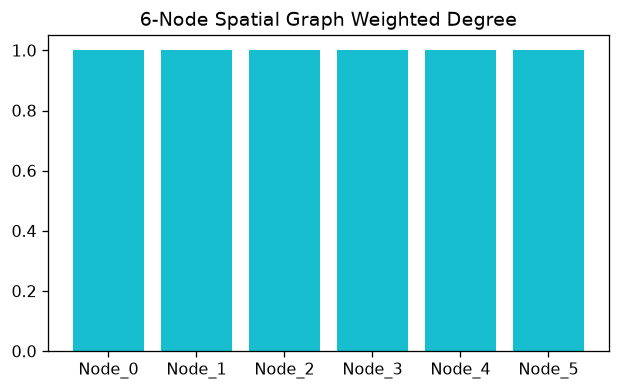

In [20]:
adj = np.load(PROJECT_ROOT / '06_Data' / 'riyadh_graph_adjacency_matrix.npy')
fig, ax = plt.subplots(figsize=(5.5, 3.5)); ax.bar([f'Node_{i}' for i in range(adj.shape[0])], adj.sum(axis=1), color='#17becf')
ax.set_title('6-Node Spatial Graph Weighted Degree'); plt.tight_layout()

## 21. Multi-Horizon SHAP Stability (24h vs 168h vs 360h)

In [21]:
sh = {}
for h in [24, 168, 360]:
    mh = XGBClassifier(n_estimators=90, max_depth=4, learning_rate=0.05, random_state=42, n_jobs=-1, eval_metric='logloss').fit(X_tr, train_df[f'target_evt_any_{h}h'].values.astype(int))
    sh[f'SHAP_{h}h'] = np.round(np.mean(np.abs(shap.TreeExplainer(mh).shap_values(X_te)), axis=0), 4)
sh_df = pd.DataFrame(sh, index=feature_cols).sort_values('SHAP_168h', ascending=False)
print(sh_df.head(10).to_string())

                                SHAP_24h  SHAP_168h  SHAP_360h
sin_doy                           0.1886     0.7716     1.3818
dust_rate_4320h                   0.1413     0.3014     0.4500
hours_since_dust                  0.0853     0.1965     0.2858
dust_rate_720h                    0.0095     0.1438     0.0483
era5_soil_moisture_7_to_28cm      0.0206     0.1145     0.1904
gust                              0.0053     0.1031     0.1422
era5_soil_moisture_0_to_7cm       0.0476     0.0877     0.0107
sat_retrieved_pm10_detrended_z    0.1760     0.0863     0.0685
pm10_calibrated_ugm3              0.2387     0.0835     0.0000
phys_vpd_kpa_roll168h             0.0240     0.0702     0.3483


## 22. Plot: Horizon Importance Shift (24h -> 168h -> 360h)

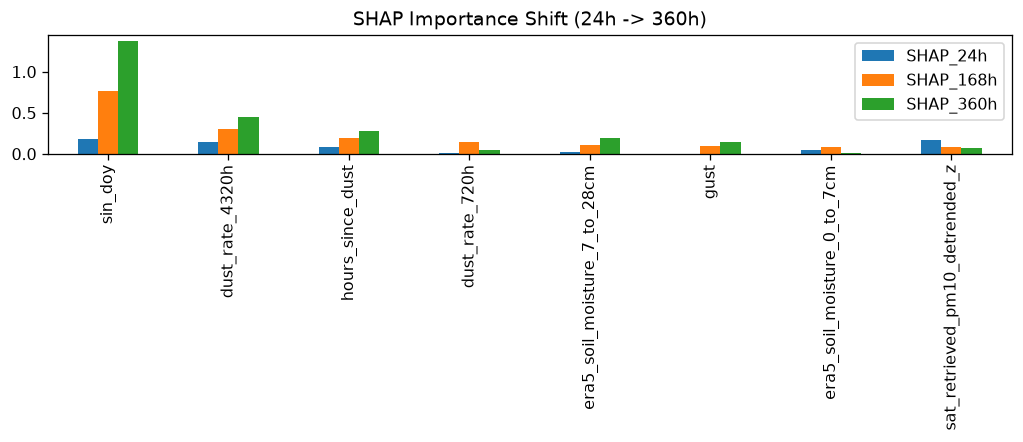

In [22]:
fig, ax = plt.subplots(figsize=(9, 4)); sh_df.head(8).plot(kind='bar', ax=ax); ax.set_title('SHAP Importance Shift (24h -> 360h)'); plt.tight_layout()

## 23. Error-Case Audit (FP vs FN on Clean Hourly Test)

In [23]:
pb = (p_te >= 0.5).astype(int); print(f'Test FP: {((pb==1)&(y_te==0)).sum()} | Test FN: {((pb==0)&(y_te==1)).sum()}')

Test FP: 1045 | Test FN: 80


## 24. Export Verification

In [24]:
assert (XAI_DIR / 'nb04_xai_clean_hourly_importance.csv').exists(); print('XAI CSV verified.')

XAI CSV verified.


## 25. Notebook 04 Summary

In [25]:
print('NB04 Complete: Full XAI executed on clean hourly dataset.')

NB04 Complete: Full XAI executed on clean hourly dataset.
